# 02 · Exploratory analysis, sampling and uncertainty
**Week 3.** Six-plus labelled charts, descriptive statistics, subgroup comparisons, a stratified sample check and cluster-bootstrap confidence intervals.

Rule for writing about these results: **observation** (what the chart shows) → **uncertainty** (how sure, the CI) → **causal claim** (only if justified; usually it is not). Every chart is saved to `reports/figures/`.

In [1]:
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import water_utils as wu
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

def save(fig, name):
    fig.tight_layout()
    fig.savefig(wu.FIGURES / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

In [2]:
p = wu.load_panel()
p["year"] = p["month"].dt.year
actual = p[p["gap_type"] == "actual"].copy()
# per-apartment comparisons use only developments whose meters cover the whole site (see notebook 01, section 8)
whole = actual[(actual["metering"] == "whole") & actual["gal_per_apt_day"].notna()].copy()
print(f"Development-months: {len(p):,} | developments: {p.tds.nunique()} | months: {p.revenue_month.min()} to {p.revenue_month.max()}")
print(f"Actual-read development-months: {len(actual):,}")
print("Developments by metering coverage:", p.drop_duplicates("tds")["metering"].value_counts().to_dict())
print(f"Actual-read months in whole-metered developments (used for per-apartment analysis): {len(whole):,}")

Development-months: 9,609 | developments: 104 | months: 2013-01 to 2025-05
Actual-read development-months: 6,396
Developments by metering coverage: {'whole': 70, 'partial': 29, 'unknown': 5}
Actual-read months in whole-metered developments (used for per-apartment analysis): 4,793


## 1. Descriptive statistics

In [3]:
cols = ["hcf_per_day", "gal_per_apt_day", "n_meters", "share_estimated", "apartments", "temp_mean", "precip_mm", "c_supply"]
desc = p[cols].describe(percentiles=[.05, .25, .5, .75, .95]).T.round(2)
desc.to_csv(wu.ROOT / "reports" / "descriptive_stats.csv")
desc

,count,mean,std,min,5%,25%,50%,75%,95%,max
hcf_per_day,8752.0,37.30,86.98,0.00,0.03,2.51,21.96,45.66,111.10,3895.00
gal_per_apt_day,8729.0,161.28,319.76,0.00,0.02,5.61,138.14,246.41,428.68,19685.54
n_meters,8752.0,3.25,4.73,1.00,1.00,1.00,2.00,3.00,15.00,40.00
share_estimated,8752.0,0.23,0.36,0.00,0.00,0.00,0.00,0.40,1.00,1.00
apartments,9586.0,503.29,597.31,10.00,35.00,120.00,168.00,693.00,1659.00,2166.00
temp_mean,8752.0,12.14,8.89,-7.79,-1.63,3.88,12.57,20.71,24.84,25.77
precip_mm,8752.0,102.65,50.04,8.30,34.40,65.00,96.60,128.70,198.90,274.20
c_supply,8752.0,137.09,129.30,14.00,29.00,59.00,99.00,175.00,339.00,1353.00


In [4]:
by_boro = (p.groupby("borough").agg(developments=("tds", "nunique"), dev_months=("tds", "size"),
                                    pct_gap_months=("is_gap", lambda s: 100 * s.mean()))
            .join(whole.groupby("borough").agg(whole_metered_devs=("tds", "nunique"),
                                               median_gal_apt_day=("gal_per_apt_day", "median"),
                                               mean_gal_apt_day=("gal_per_apt_day", "mean")))
            .round(1))
by_boro.to_csv(wu.ROOT / "reports" / "subgroup_borough.csv")
by_boro

,developments,dev_months,pct_gap_months,whole_metered_devs,median_gal_apt_day,mean_gal_apt_day
borough,,,,,,
BRONX,28,2234,29.9,20.0,271.4,289.7
BROOKLYN,30,2992,36.7,18.0,214.7,218.5
MANHATTAN,34,2853,33.4,25.0,186.7,231.0
QUEENS,11,1393,35.2,7.0,164.6,189.5
STATEN ISLAND,1,137,1.5,NaN,NaN,NaN


## 2. Six core visualisations (plus two extra)
### Fig 1 · Citywide consumption over time, and how much of it is measured

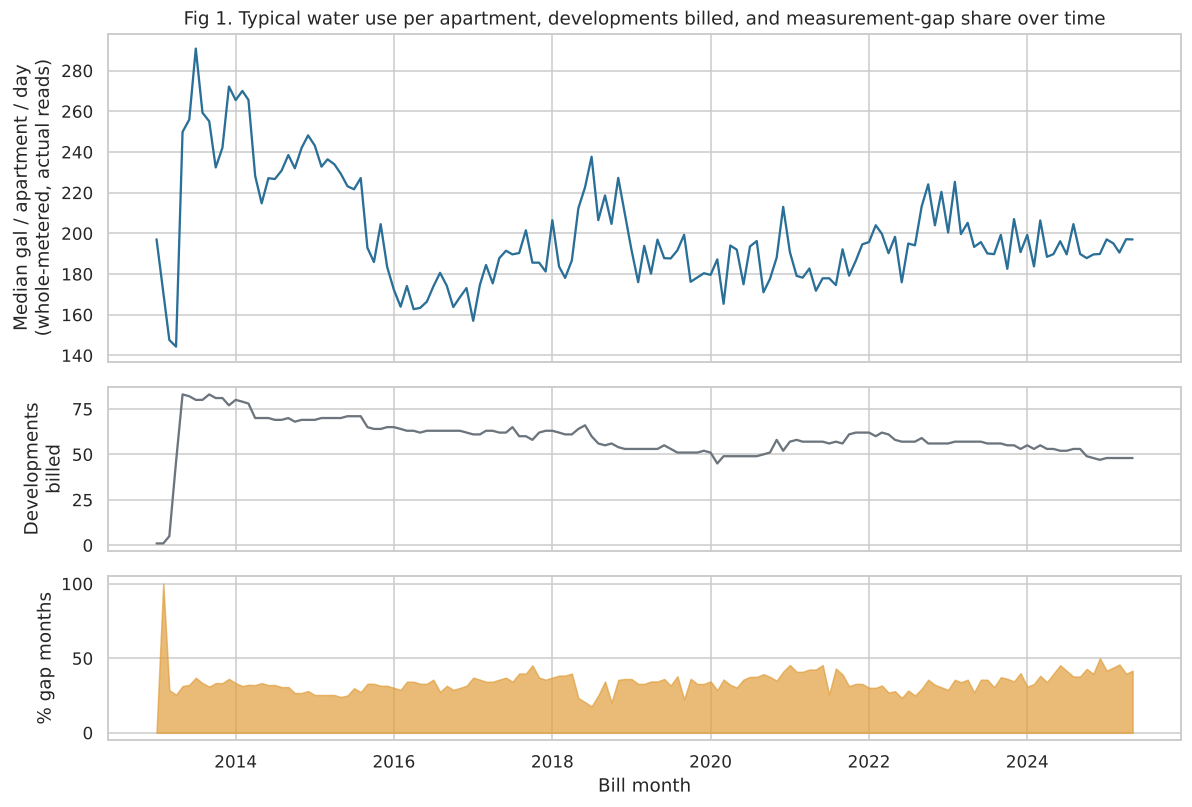

Median gal/apt/day: 2014 = 238, 2024 = 190


In [5]:
# Robust citywide picture: the MEDIAN development (whole-metered, actual reads), not the total.
# The total would mostly track how many developments are billed each month (88 in 2013, ~50 in 2025)
# and a few extreme bills, not real changes in use.
med_use = whole.groupby("month")["gal_per_apt_day"].median()
n_devs = p[p.n_meters.notna()].groupby("month")["tds"].nunique()
gap_share = p.groupby("month")["is_gap"].mean() * 100
for s_ in (med_use, n_devs, gap_share):
    s_.index = s_.index.to_timestamp()
fig, ax = plt.subplots(3, 1, figsize=(11, 7.5), sharex=True, gridspec_kw={"height_ratios": [2, 1, 1]})
ax[0].plot(med_use.index, med_use.values, color="#2a6f97")
ax[0].set_ylabel("Median gal / apartment / day\n(whole-metered, actual reads)")
ax[0].set_title("Fig 1. Typical water use per apartment, developments billed, and measurement-gap share over time")
ax[1].plot(n_devs.index, n_devs.values, color="#6c757d")
ax[1].set_ylabel("Developments\nbilled")
ax[2].fill_between(gap_share.index, gap_share.values, color="#e09f3e", alpha=.7)
ax[2].set_ylabel("% gap months"); ax[2].set_xlabel("Bill month")
save(fig, "fig1_citywide_trend_and_gaps")
print(f"Median gal/apt/day: 2014 = {whole[whole.year == 2014].gal_per_apt_day.median():.0f}, "
      f"2024 = {whole[whole.year == 2024].gal_per_apt_day.median():.0f}")

**How to annotate:** describe the trend in typical use, the fall in the number of developments with metered bills, and the rising gap share in 2024–2025. A citywide *total* would be misleading here because the set of billed developments changes over time.

### Fig 2 · Distribution of water use per apartment

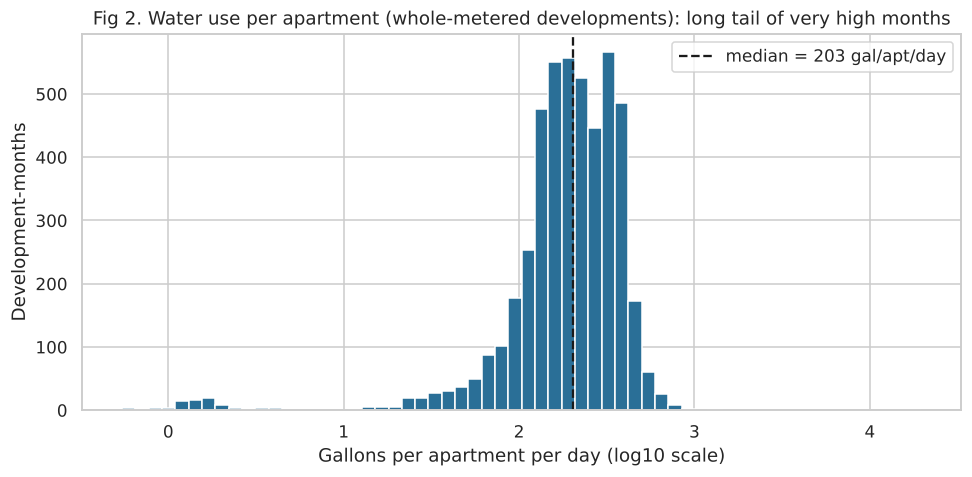

In [6]:
g = whole["gal_per_apt_day"].replace([np.inf, -np.inf], np.nan).dropna()
g = g[g > 0]
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(np.log10(g), bins=60, color="#2a6f97")
med = g.median()
ax.axvline(np.log10(med), color="k", ls="--", label=f"median = {med:,.0f} gal/apt/day")
ax.set_xlabel("Gallons per apartment per day (log10 scale)"); ax.set_ylabel("Development-months")
ax.set_title("Fig 2. Water use per apartment (whole-metered developments): long tail of very high months")
ax.legend(); save(fig, "fig2_distribution_gal_per_apt")

### Fig 3 · Subgroup comparison by borough

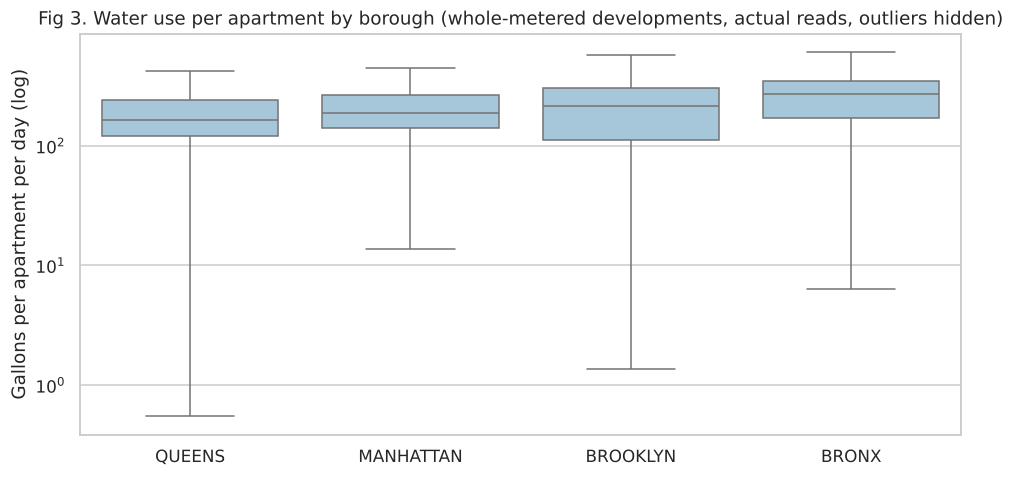

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.5))
order = whole.groupby("borough")["gal_per_apt_day"].median().sort_values().index
sns.boxplot(data=whole[whole.gal_per_apt_day > 0], x="borough", y="gal_per_apt_day", order=order,
            showfliers=False, color="#9ecae1", ax=ax)
ax.set_yscale("log"); ax.set_xlabel(""); ax.set_ylabel("Gallons per apartment per day (log)")
ax.set_title("Fig 3. Water use per apartment by borough (whole-metered developments, actual reads, outliers hidden)")
save(fig, "fig3_borough_boxplot")

### Fig 4 · Measurement gaps vs real reads, by year

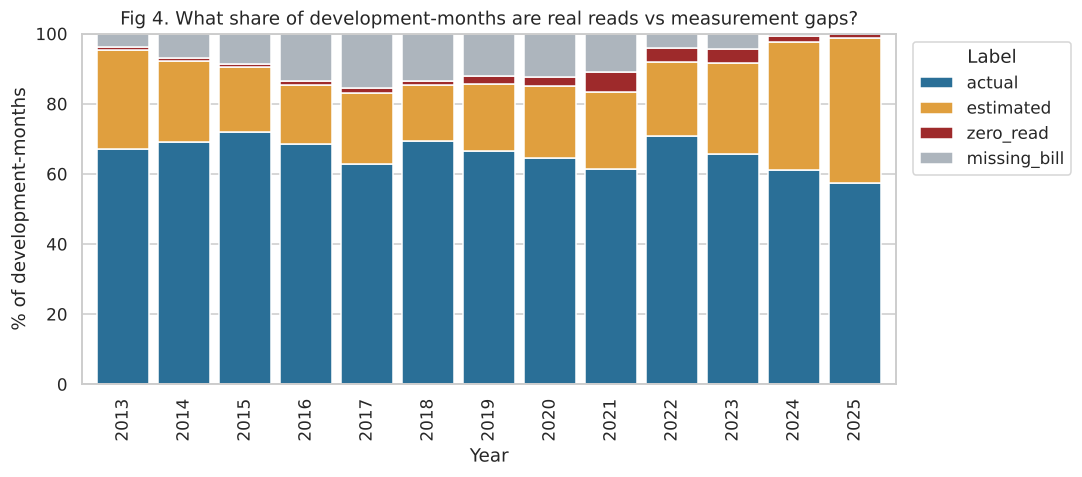

In [8]:
comp = pd.crosstab(p["year"], p["gap_type"], normalize="index").mul(100)
comp = comp[[c for c in ["actual", "estimated", "zero_read", "missing_bill"] if c in comp]]
fig, ax = plt.subplots(figsize=(10, 4.5))
comp.plot(kind="bar", stacked=True, ax=ax, color=["#2a6f97", "#e09f3e", "#9e2a2b", "#adb5bd"][:comp.shape[1]], width=.85)
ax.set_ylabel("% of development-months"); ax.set_xlabel("Year")
ax.set_title("Fig 4. What share of development-months are real reads vs measurement gaps?")
ax.legend(title="Label", bbox_to_anchor=(1.01, 1), loc="upper left")
save(fig, "fig4_gap_composition_by_year")

### Fig 5 · Seasonality and weather

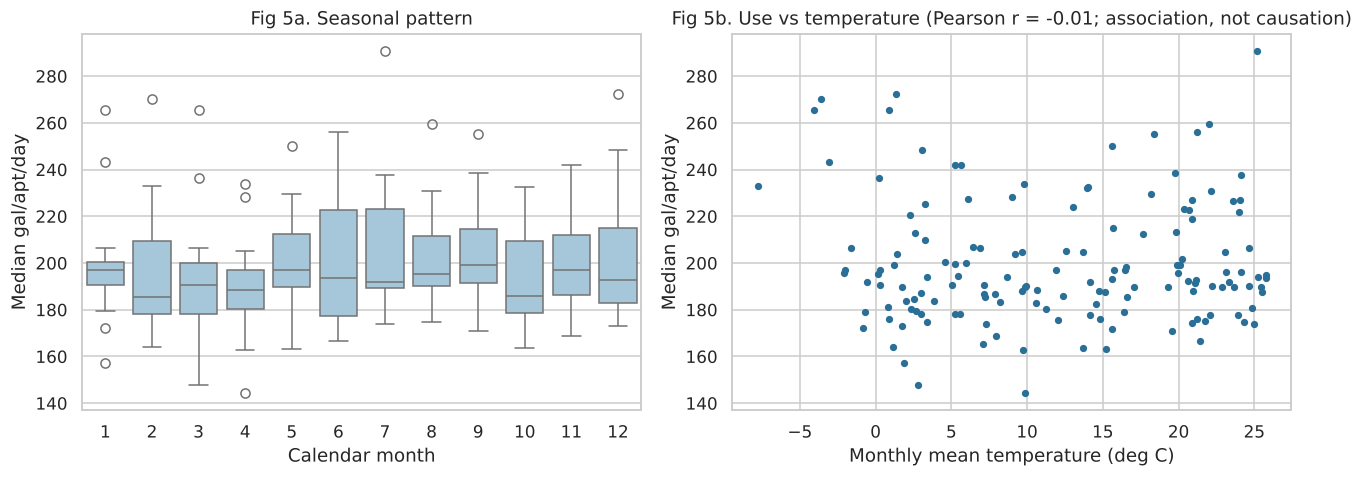

In [9]:
mm = whole.groupby("revenue_month").agg(gal=("gal_per_apt_day", "median"), temp=("temp_mean", "first"))
mm["moy"] = pd.PeriodIndex(mm.index, freq="M").month
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
sns.boxplot(data=mm, x="moy", y="gal", color="#9ecae1", ax=ax[0])
ax[0].set_xlabel("Calendar month"); ax[0].set_ylabel("Median gal/apt/day")
ax[0].set_title("Fig 5a. Seasonal pattern")
ax[1].scatter(mm["temp"], mm["gal"], s=14, color="#2a6f97")
r = mm[["temp", "gal"]].corr().iloc[0, 1]
ax[1].set_xlabel("Monthly mean temperature (deg C)"); ax[1].set_ylabel("Median gal/apt/day")
ax[1].set_title(f"Fig 5b. Use vs temperature (Pearson r = {r:.2f}; association, not causation)")
save(fig, "fig5_seasonality_weather")

### Fig 6 · Reported disruptions (311) by borough

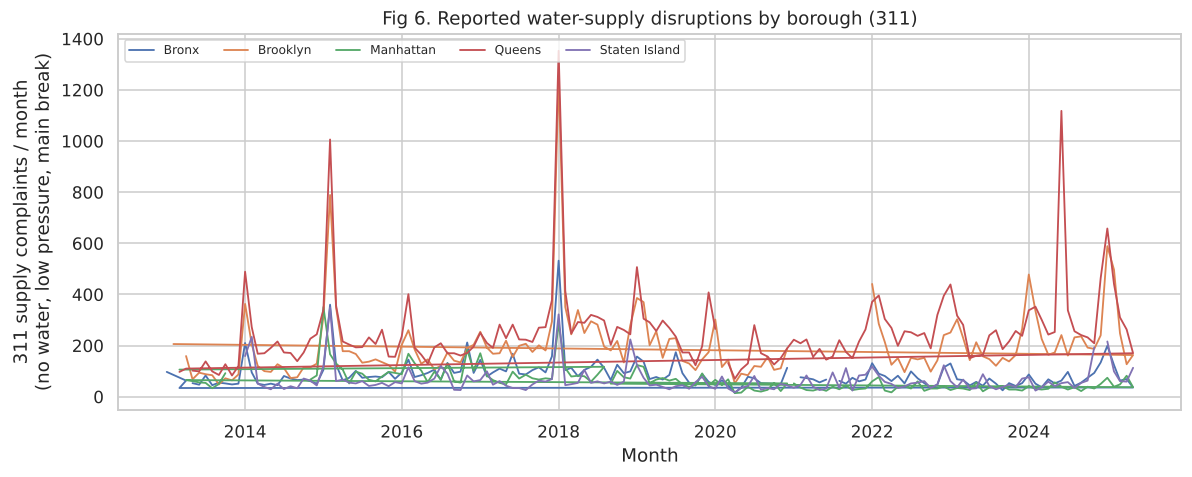

In [10]:
bm = p.drop_duplicates(["borough", "revenue_month"])[["borough", "month", "c_supply", "c_no_water", "c_low_pressure", "c_main_break", "c_leak", "c_hydrant"]]
bm = bm.assign(month=bm["month"].dt.to_timestamp())
fig, ax = plt.subplots(figsize=(11, 4.5))
for b, gb in bm.groupby("borough"):
    ax.plot(gb["month"], gb["c_supply"], label=b.title(), lw=1.2)
ax.set_ylabel("311 supply complaints / month\n(no water, low pressure, main break)"); ax.set_xlabel("Month")
ax.set_title("Fig 6. Reported water-supply disruptions by borough (311)")
ax.legend(ncol=5, fontsize=8, loc="upper left"); save(fig, "fig6_311_by_borough")

In [11]:
# Complaint composition (which kinds of disruption dominate?)
bm[["c_no_water", "c_low_pressure", "c_main_break", "c_leak", "c_hydrant"]].sum().to_frame("complaints 2013-May 2025")

,complaints 2013-May 2025
c_no_water,41982.0
c_low_pressure,20295.0
c_main_break,36733.0
c_leak,134577.0
c_hydrant,373138.0


### Fig 7 (extra) · Which developments have recurring gaps?

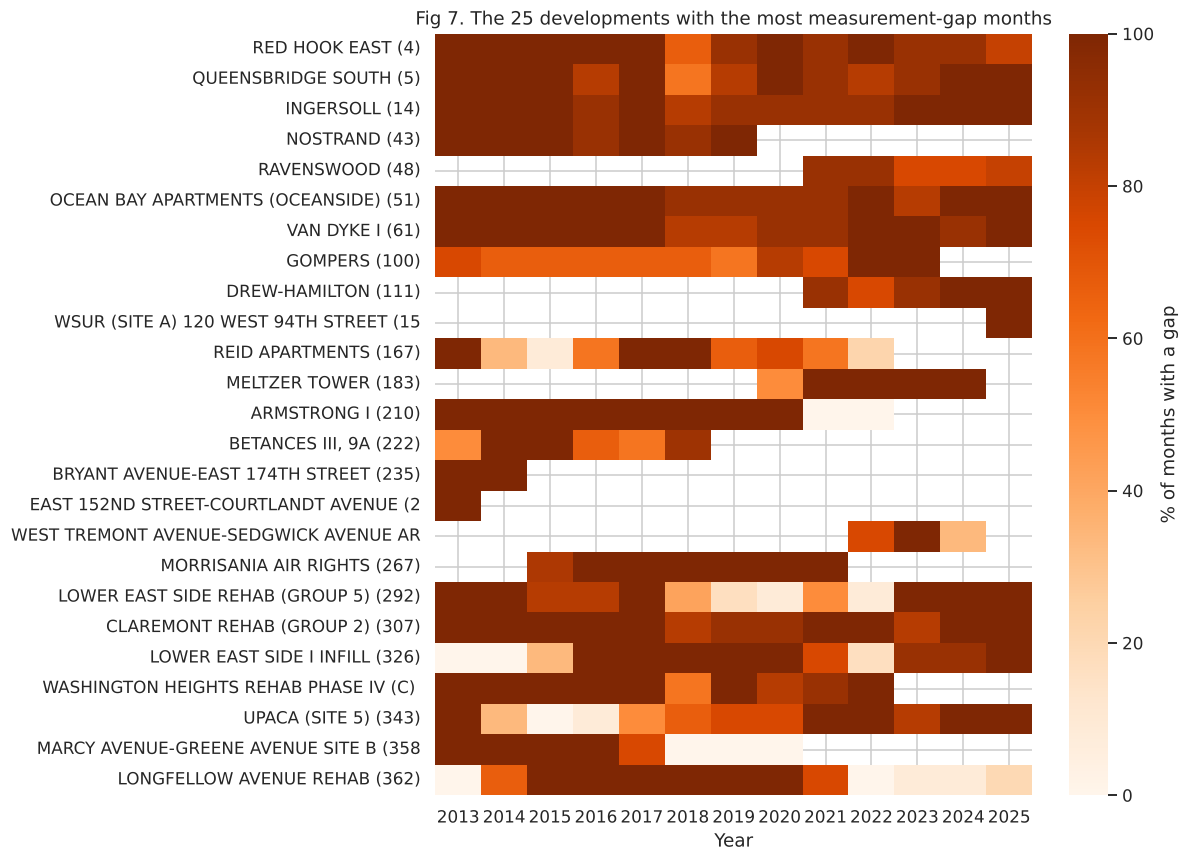

In [12]:
top = p.groupby("tds")["is_gap"].mean().sort_values(ascending=False).head(25).index
hm = (p[p.tds.isin(top)].groupby(["tds", "year"])["is_gap"].mean().mul(100).unstack())
names = p.groupby("tds")["development"].first()
hm.index = [f"{names.get(t) if pd.notna(names.get(t)) else 'TDS'} ({t})"[:38] for t in hm.index]
fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(hm, cmap="Oranges", vmin=0, vmax=100, cbar_kws={"label": "% of months with a gap"}, ax=ax)
ax.set_xlabel("Year"); ax.set_ylabel("")
ax.set_title("Fig 7. The 25 developments with the most measurement-gap months")
save(fig, "fig7_recurring_gap_heatmap")

## 3. Challenge an initial assumption
**Assumption:** "an estimated bill is roughly as good as a real one."
**Test:** compare month-to-month changes and levels for estimated vs actual months in the same developments. If estimated months are much smoother (small changes) or systematically different, they cannot be used to detect incidents.

In [13]:
q = p.sort_values(["tds", "month"]).copy()
q["abs_change"] = q.groupby("tds")["hcf_per_day"].diff().abs() / q.groupby("tds")["hcf_per_day"].shift()
cmp_ = (q[q.gap_type.isin(["actual", "estimated"])]
          .groupby("gap_type").agg(dev_months=("tds", "size"),
                                   median_abs_change_pct=("abs_change", lambda s: 100 * s.median()),
                                   median_hcf_per_day=("hcf_per_day", "median")).round(2))
cmp_

,dev_months,median_abs_change_pct,median_hcf_per_day
gap_type,,,
actual,6396,6.80,26.42
estimated,2155,2.66,12.03


## 4. Uncertainty: cluster-bootstrap 95% confidence intervals
Months from the same development are correlated, so we **resample whole developments** (2,000 times), not single rows. Resampling rows would make the intervals falsely narrow.

In [14]:
rows = []
a2 = whole.replace([np.inf, -np.inf], np.nan).dropna(subset=["gal_per_apt_day"])
for b in sorted(p["borough"].dropna().unique()):
    gest, glo, ghi = wu.cluster_bootstrap_mean(p[p.borough == b], "is_gap")
    row = {"borough": b, "developments": p.loc[p.borough == b, "tds"].nunique(),
           "pct_gap": 100 * gest, "gap_ci_low": 100 * glo, "gap_ci_high": 100 * ghi}
    gb = a2[a2.borough == b]
    row["whole_metered_devs"] = gb.tds.nunique()
    if gb.tds.nunique() >= 3:          # too few developments -> no meaningful interval
        est, lo, hi = wu.cluster_bootstrap_mean(gb, "gal_per_apt_day")
        row.update({"mean_gal_apt_day": est, "ci_low": lo, "ci_high": hi})
    rows.append(row)
ci = pd.DataFrame(rows).round(1)
ci.to_csv(wu.ROOT / "reports" / "bootstrap_ci_by_borough.csv", index=False)
ci

,borough,developments,pct_gap,gap_ci_low,gap_ci_high,whole_metered_devs,mean_gal_apt_day,ci_low,ci_high
0,BRONX,28,29.9,15.8,45.2,20,289.7,231.8,356.5
1,BROOKLYN,30,36.7,23.7,51.6,18,218.5,161.4,272.7
2,MANHATTAN,34,33.4,21.5,44.8,25,231.0,184.8,280.7
3,QUEENS,11,35.2,16.2,58.5,7,189.5,122.1,270.5
4,STATEN ISLAND,1,1.5,1.5,1.5,0,NaN,NaN,NaN


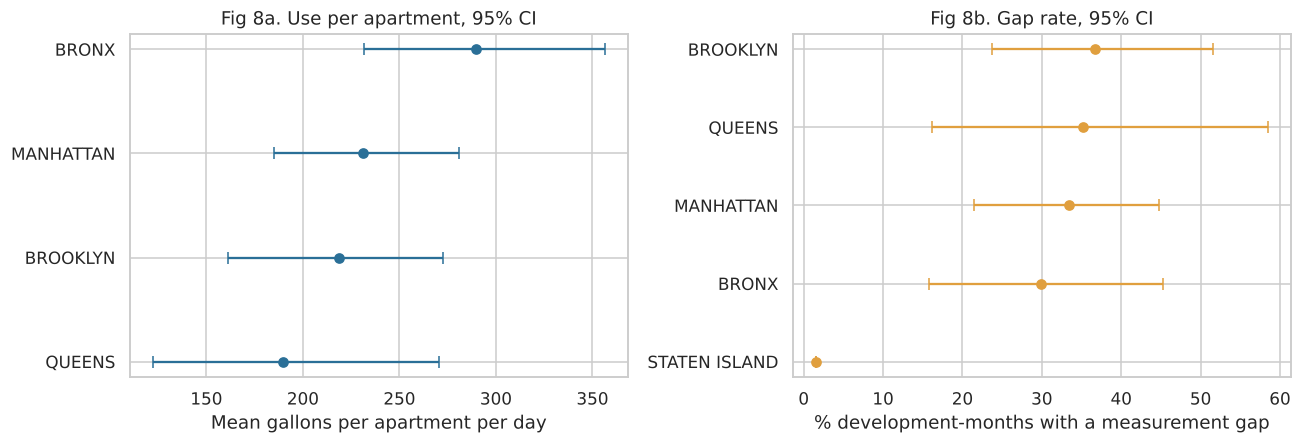

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
c2 = ci.dropna(subset=["mean_gal_apt_day"]).sort_values("mean_gal_apt_day")
ax[0].errorbar(c2["mean_gal_apt_day"], c2["borough"], xerr=[c2.mean_gal_apt_day - c2.ci_low, c2.ci_high - c2.mean_gal_apt_day],
               fmt="o", color="#2a6f97", capsize=4)
ax[0].set_xlabel("Mean gallons per apartment per day"); ax[0].set_title("Fig 8a. Use per apartment, 95% CI")
c3 = ci.sort_values("pct_gap")
ax[1].errorbar(c3["pct_gap"], c3["borough"], xerr=[c3.pct_gap - c3.gap_ci_low, c3.gap_ci_high - c3.pct_gap],
               fmt="o", color="#e09f3e", capsize=4)
ax[1].set_xlabel("% development-months with a measurement gap"); ax[1].set_title("Fig 8b. Gap rate, 95% CI")
save(fig, "fig8_bootstrap_ci")

In [16]:
# Difference between the highest- and lowest-use boroughs (among boroughs with >= 5 whole-metered developments)
cc = ci[ci.whole_metered_devs >= 5].sort_values("mean_gal_apt_day")
hi_b, lo_b = cc.iloc[-1]["borough"], cc.iloc[0]["borough"]
d, dlo, dhi = wu.cluster_bootstrap_diff(a2, "gal_per_apt_day", "borough", hi_b, lo_b)
print(f"{hi_b} minus {lo_b}: {d:.1f} gal/apt/day, 95% CI [{dlo:.1f}, {dhi:.1f}]")
print("CI excludes 0" if dlo > 0 or dhi < 0 else "CI includes 0: no clear difference")

BRONX minus QUEENS: 100.2 gal/apt/day, 95% CI [-6.8, 197.3]
CI includes 0: no clear difference


## 5. Sampling: how well does a sample of developments reproduce the full picture?
If NYCHA could audit only some developments, how wrong would its estimates be? We draw **25% of developments** 1,000 times in two ways and compare the spread of the estimates with the full-data value:
- **Simple random sample** of developments
- **Stratified sample**: 25% within each borough, so every borough keeps its share

Estimates: citywide share of gap months (all developments) and median gal/apt/day (whole-metered developments). A narrower 95% range = a more reliable sampling design.

In [17]:
rng = np.random.default_rng(2050)
devs = p.drop_duplicates("tds")[["tds", "borough"]].reset_index(drop=True)
gap_by_dev = p.groupby("tds")["is_gap"].agg(["sum", "count"])
full_gap = 100 * gap_by_dev["sum"].sum() / gap_by_dev["count"].sum()
full_med = whole["gal_per_apt_day"].median()

def estimates(ids):
    g = gap_by_dev.loc[gap_by_dev.index.intersection(ids)]
    w = whole[whole.tds.isin(ids)]["gal_per_apt_day"]
    return 100 * g["sum"].sum() / g["count"].sum(), (w.median() if len(w) else np.nan)

res = {"simple random": [], "stratified by borough": []}
n_take = round(0.25 * len(devs))
for _ in range(1000):
    res["simple random"].append(estimates(rng.choice(devs.tds, n_take, replace=False)))
    ids = np.concatenate([rng.choice(g.tds, max(1, round(0.25 * len(g))), replace=False)
                          for _, g in devs.groupby("borough")])
    res["stratified by borough"].append(estimates(ids))

rows = []
for k, v in res.items():
    v = np.array(v, dtype=float)
    rows.append({"design": k, "devs_per_sample": n_take,
                 "gap_%_full": full_gap, "gap_%_mean": np.nanmean(v[:, 0]),
                 "gap_%_95%_range": f"{np.nanpercentile(v[:,0], 2.5):.1f} - {np.nanpercentile(v[:,0], 97.5):.1f}",
                 "median_gal_full": full_med, "median_gal_mean": np.nanmean(v[:, 1]),
                 "median_gal_95%_range": f"{np.nanpercentile(v[:,1], 2.5):.0f} - {np.nanpercentile(v[:,1], 97.5):.0f}"})
strat = pd.DataFrame(rows).round(1)
strat.to_csv(wu.ROOT / "reports" / "stratified_sample_check.csv", index=False)
strat

,design,devs_per_sample,gap_%_full,gap_%_mean,gap_%_95%_range,median_gal_full,median_gal_mean,median_gal_95%_range
0,simple random,26,33.4,33.9,22.0 - 47.2,202.6,205.6,156 - 276
1,stratified by borough,26,33.4,32.5,20.5 - 44.5,202.6,205.2,155 - 270


## 6. Refine the questions (write these into the interim memo)
- Which boroughs/developments differ, and are the differences larger than the CIs?
- Is the gap rate itself the bigger reliability problem than abnormal use?
- Does use follow temperature closely enough that weather must be in the model? (Fig 5)
- What did the assumption check in section 3 change about how we treat estimated bills?